# Double-blink detection

## 1. Setup

In [1]:
%matplotlib inline
from pathlib import Path
from datetime import datetime, timedelta, timezone
import json
import cloudpickle
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay,
)
mne.set_log_level("WARNING")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
ROOT = Path.cwd()
if not (ROOT / "environment.yml").is_file():
    ROOT = ROOT.parent
assert (ROOT / "environment.yml").is_file(), "Open the project root or this notebook folder."
EEG_DIR = ROOT / "data/EEG Data/Experiment 3 - Double Blinking"
STIM_DIR = ROOT / "data/Stimulation Data/Experiment 3 - Double Blinking"
OUTPUT = ROOT / "results/blink_pipeline_all_channels"
TRAIN_TRIAL, VALID_TRIAL, TEST_TRIAL = 1, 2, 3
TRIALS = [TRAIN_TRIAL, VALID_TRIAL, TEST_TRIAL]
DROP_CHANNELS = ["M1", "M2", "O2"]
PREVIEW_CHANNELS = ["Fp1", "Fp2"]
CLOCK_OFFSET_S = 0.0
BANDPASS, FILTER_ORDER, SAMPLE_RATE = [0.5, 10], 4, 100
BASELINE_SECONDS, EPOCH_SECONDS, BIN_SECONDS = 0.2, 1.0, 0.05
assert EEG_DIR.exists(), "Check that the EEG data folder is present."
assert len(set(TRIALS)) == 3

## 2. Load continuous recordings

In [3]:
def load_recording(path):
    raw = mne.io.read_raw_ant(path, preload=True, verbose="error")
    raw.drop_channels([ch for ch in raw.ch_names if ch.upper() in DROP_CHANNELS])
    original_start = raw.info["meas_date"]
    first_sample, sample_count = 0, raw.n_times
    segment_file = path.with_suffix(".seg")
    if segment_file.exists():
        lines = segment_file.read_text().splitlines()
        assert len(lines) == 2 and int(lines[0].split("=")[1]) == 2
        day, fraction, count = lines[1].split()
        sample_count = int(count)
        first_sample = raw.n_times - sample_count
        assert (first_sample, sample_count) == (22710, 126887)
        resumed = datetime(1899, 12, 30, tzinfo=timezone.utc) + timedelta(days=float(day), seconds=float(fraction))
        raw = mne.io.RawArray(raw.get_data(start=first_sample), raw.info.copy(), verbose="error")
        raw.set_meas_date(resumed)
    timing = {"original_start_utc": original_start.isoformat(),
              "segment_start_utc": raw.info["meas_date"].isoformat(),
              "retained_start_sample": int(first_sample), "retained_samples": int(sample_count),
              "original_sample_rate_hz": raw.info["sfreq"],
              "segment_file": str(segment_file.relative_to(ROOT)) if segment_file.exists() else None}
    return raw, timing

In [4]:
raws, logs, sources = {}, {}, []
for trial in TRIALS:
    eeg_files = list((EEG_DIR / f"Trial {trial}").glob("*.cnt"))
    log_files = list((STIM_DIR / f"Trial {trial}").glob("*_all.csv"))
    assert len(eeg_files) == len(log_files) == 1
    raw, timing = load_recording(eeg_files[0])
    log = pd.read_csv(log_files[0], keep_default_na=False)
    assert log["seq"].is_unique and (log["offset_epoch_ms"] > log["onset_epoch_ms"]).all()
    assert (log["onset_epoch_ms"].to_numpy()[1:] >= log["offset_epoch_ms"].to_numpy()[:-1]).all()
    assert set(log["stimulus_type"]) == {"", "other", "trigger"}
    assert log.loc[log["stimulus_type"].eq("trigger"), "word"].eq("double blink").all()
    assert np.isfinite(raw.get_data()).all()
    raws[trial], logs[trial] = raw, log
    sources.append({"trial": trial, "eeg_file": str(eeg_files[0].relative_to(ROOT)),
                    "stimulus_file": str(log_files[0].relative_to(ROOT)), **timing})
display_channels = raws[TRAIN_TRIAL].ch_names.copy()
MODEL_CHANNELS = display_channels.copy()
assert len(display_channels) == 21 and all(raw.ch_names == display_channels for raw in raws.values())
assert {raw.info["sfreq"] for raw in raws.values()} == {1000}
display(pd.DataFrame(sources)[["trial", "segment_start_utc", "retained_start_sample", "retained_samples"]].set_index("trial"))

,segment_start_utc,retained_start_sample,retained_samples
trial,,,
1,2026-11-08T02:02:22.985121+00:00,22710,126887
2,2026-11-08T02:06:32.922243+00:00,0,188322
3,2026-11-08T02:11:34.971136+00:00,0,184367


## 3. Filter and resample

In [5]:
cleaned = {}
for trial, raw in raws.items():
    filtered = raw.copy().filter(*BANDPASS, method="iir", phase="zero",
                                iir_params={"order": FILTER_ORDER, "ftype": "butter", "output": "sos"}, verbose="error")
    filtered.resample(SAMPLE_RATE, verbose="error")
    assert filtered.ch_names == display_channels and filtered.info["sfreq"] == SAMPLE_RATE
    assert np.isfinite(filtered.get_data()).all()
    cleaned[trial] = filtered
print("0.5–10 Hz, fourth-order zero-phase Butterworth; 100 Hz; original reference; no ICA.")

0.5–10 Hz, fourth-order zero-phase Butterworth; 100 Hz; original reference; no ICA.


## 4. Check development-trial alignment

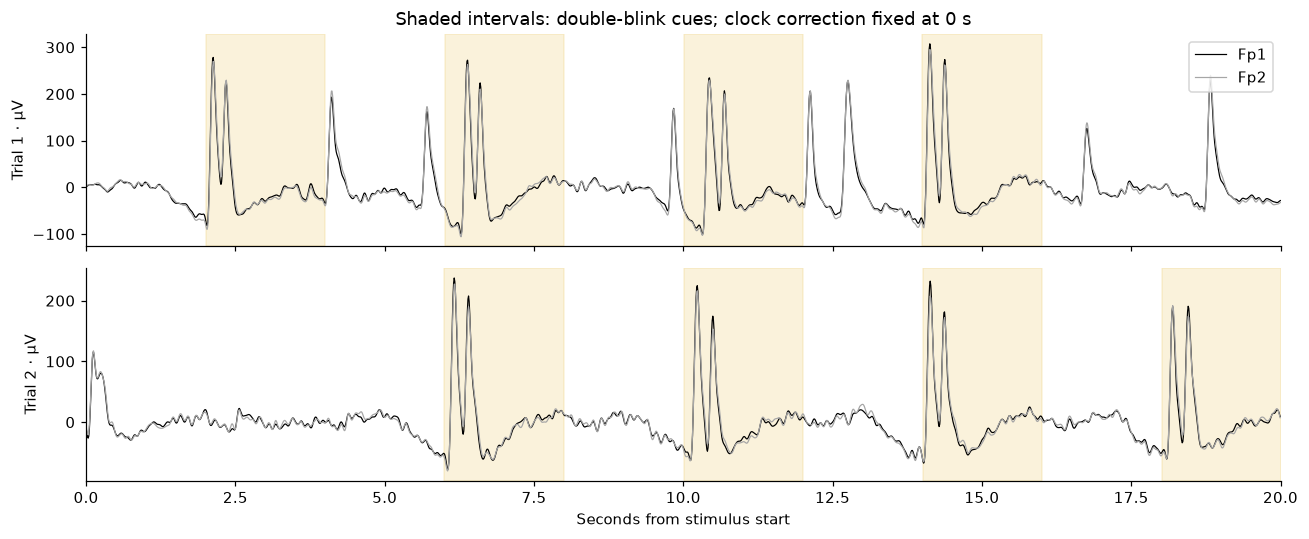

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, trial in zip(axes, [TRAIN_TRIAL, VALID_TRIAL]):
    raw, log = cleaned[trial], logs[trial]
    origin = pd.to_datetime(log["onset_epoch_ms"].iloc[0], unit="ms", utc=True)
    times = raw.times + (pd.Timestamp(raw.info["meas_date"]) - origin).total_seconds() + CLOCK_OFFSET_S
    visible = (times >= 0) & (times <= 20)
    for channel, color in zip(PREVIEW_CHANNELS, ["black", "0.65"]):
        ax.plot(times[visible], raw.get_data(picks=[channel])[0, visible] * 1e6, color=color, lw=0.8, label=channel)
    for event in log.itertuples():
        onset = (event.onset_epoch_ms - log["onset_epoch_ms"].iloc[0]) / 1000
        offset = (event.offset_epoch_ms - log["onset_epoch_ms"].iloc[0]) / 1000
        if event.stimulus_type == "trigger" and onset < 20:
            ax.axvspan(onset, min(20, offset), color="#eac14c", alpha=0.2)
    ax.set(xlim=(0, 20), ylabel=f"Trial {trial} · µV")
axes[0].legend(loc="upper right")
axes[0].set_title("Shaded intervals: double-blink cues; clock correction fixed at 0 s")
axes[-1].set_xlabel("Seconds from stimulus start")
fig.tight_layout()
plt.show()

## 5. Make one-second examples

In [7]:
def make_epochs(raw, log, trial):
    sfreq = raw.info["sfreq"]
    start_ms = pd.Timestamp(raw.info["meas_date"]).timestamp() * 1000
    onset = (log["onset_epoch_ms"].to_numpy() - start_ms) / 1000 - CLOCK_OFFSET_S
    offset = (log["offset_epoch_ms"].to_numpy() - start_ms) / 1000 - CLOCK_OFFSET_S
    starts = np.ceil(onset * sfreq).astype(int)
    n_before, n_after = round(BASELINE_SECONDS * sfreq), round(EPOCH_SECONDS * sfreq)
    keep = (starts >= n_before) & (starts + n_after <= raw.n_times)
    keep &= (starts + n_after) / sfreq <= offset
    meta = log.loc[keep, ["seq", "stimulus_type", "complete"]].reset_index(drop=True)
    meta = meta.rename(columns={"seq": "event_id", "complete": "log_complete"})
    codes = meta["stimulus_type"].map({"": 1, "other": 2, "trigger": 3}).to_numpy()
    meta["stimulus_type"] = meta["stimulus_type"].map({"": "blank", "other": "na", "trigger": "double blink"})
    meta["label"], meta["trial"] = (codes == 3).astype(int), trial
    meta["start_sample"] = starts[keep]
    meta["onset_in_eeg_s"], meta["offset_in_eeg_s"] = onset[keep], offset[keep]
    meta["start_s"], meta["end_s"] = starts[keep] / sfreq, (starts[keep] + n_after) / sfreq
    events = np.column_stack([starts[keep], np.zeros(keep.sum(), int), codes])
    return mne.Epochs(raw, events, {"blank": 1, "na": 2, "double blink": 3},
                      tmin=-BASELINE_SECONDS, tmax=EPOCH_SECONDS - 1 / sfreq,
                      baseline=(-BASELINE_SECONDS, -1 / sfreq), metadata=meta,
                      preload=True, reject_by_annotation=True, verbose="error")

In [8]:
epochs = {trial: make_epochs(cleaned[trial], logs[trial], trial) for trial in TRIALS}
X = np.concatenate([epochs[t].get_data(picks=MODEL_CHANNELS)[..., epochs[t].times >= 0] for t in TRIALS]) * 1e6
manifest = pd.concat([epochs[t].metadata for t in TRIALS], ignore_index=True)
manifest["split"] = manifest["trial"].map({TRAIN_TRIAL: "Train", VALID_TRIAL: "Validation", TEST_TRIAL: "Test"})
y = manifest["label"].to_numpy()
train_mask, valid_mask, test_mask = [manifest["trial"].eq(t).to_numpy() for t in TRIALS]
X_train, y_train = X[train_mask], y[train_mask]
X_valid, y_valid = X[valid_mask], y[valid_mask]
X_test, y_test = X[test_mask], y[test_mask]
assert X.shape == (237, 21, 100) and np.isfinite(X).all()
assert [len(epochs[t]) for t in TRIALS] == [59, 89, 89]
assert [int(y[mask].sum()) for mask in [train_mask, valid_mask, test_mask]] == [22, 33, 33]
assert (manifest["start_s"] >= manifest["onset_in_eeg_s"]).all()
assert (manifest["end_s"] <= manifest["offset_in_eeg_s"]).all()
for trial, ep in epochs.items():
    np.testing.assert_allclose(ep.get_data()[..., ep.times < 0].mean(-1), 0, atol=1e-12)
    assert np.all(np.diff(manifest.loc[manifest["trial"].eq(trial), "start_sample"]) >= SAMPLE_RATE)
display(pd.crosstab([manifest["trial"], manifest["split"]], manifest["stimulus_type"]))

,stimulus_type,blank,double blink,na
trial,split,,,
1,Train,30,22,7
2,Validation,45,33,11
3,Test,45,33,11


## 6. Train on Trial 1

In [9]:
def time_bins(X, sfreq, bin_seconds):
    width = round(sfreq * bin_seconds)
    return X.reshape(len(X), X.shape[1], -1, width).mean(-1).reshape(len(X), -1)


transform = FunctionTransformer(time_bins, kw_args={"sfreq": SAMPLE_RATE, "bin_seconds": BIN_SECONDS})
assert transform.transform(X_train).shape[1] == 420
models = {
    "Logistic regression": make_pipeline(clone(transform), StandardScaler(),
                                          LogisticRegression(class_weight="balanced", max_iter=5000)),
    "Shrinkage LDA": make_pipeline(clone(transform), StandardScaler(),
                                   LDA(solver="lsqr", shrinkage="auto", priors=[0.5, 0.5])),
    "Random forest": make_pipeline(clone(transform),
                                   RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
}
fitted = {name: clone(model).fit(X_train, y_train) for name, model in models.items()}
print("Trained three models using 420 time-bin features per epoch.")

Trained three models using 420 time-bin features per epoch.


## 7. Validate on Trial 2

In [10]:
def prediction_scores(model, features):
    if hasattr(model, "decision_function"):
        return model.decision_function(features)
    return model.predict_proba(features)[:, 1]


def evaluate(actual, predicted, scores):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Double-blink precision": precision_score(actual, predicted, zero_division=0),
        "Double-blink recall": recall_score(actual, predicted, zero_division=0),
        "Double-blink F1": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, scores),
        "Average precision": average_precision_score(actual, scores),
    }

Selected: Random forest


,Accuracy,Balanced accuracy,Double-blink precision,Double-blink recall,Double-blink F1,ROC AUC,Average precision
Model,,,,,,,
Random forest,0.966,0.955,1.000,0.909,0.952,0.997,0.995
Logistic regression,0.955,0.939,1.000,0.879,0.935,0.998,0.997
Shrinkage LDA,0.933,0.915,0.966,0.848,0.903,0.990,0.982


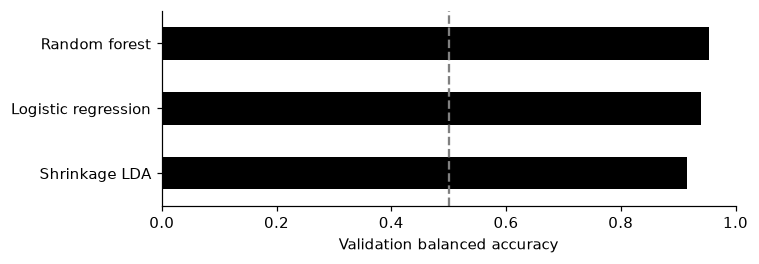

In [11]:
validation_rows = []
for name, model in fitted.items():
    metrics = evaluate(y_valid, model.predict(X_valid), prediction_scores(model, X_valid))
    validation_rows.append({"Model": name, **metrics})
validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values(
    ["Balanced accuracy", "Double-blink precision"], ascending=False, kind="stable")
best_name = validation_results.index[0]
display(validation_results.style.format("{:.3f}"))
print("Selected:", best_name)
ax = validation_results["Balanced accuracy"].sort_values().plot.barh(color="black", figsize=(7, 2.5))
ax.axvline(0.5, color="gray", linestyle="--")
ax.set(xlim=(0, 1), xlabel="Validation balanced accuracy", ylabel="")
plt.tight_layout()
plt.show()

## 8. Refit on Trials 1–2 and test on Trial 3

,Selected model,Always no double blink
Accuracy,1.000,0.629
Balanced accuracy,1.000,0.500
Double-blink precision,1.000,0.000
Double-blink recall,1.000,0.000
Double-blink F1,1.000,0.000
ROC AUC,1.000,0.500
Average precision,1.000,0.371


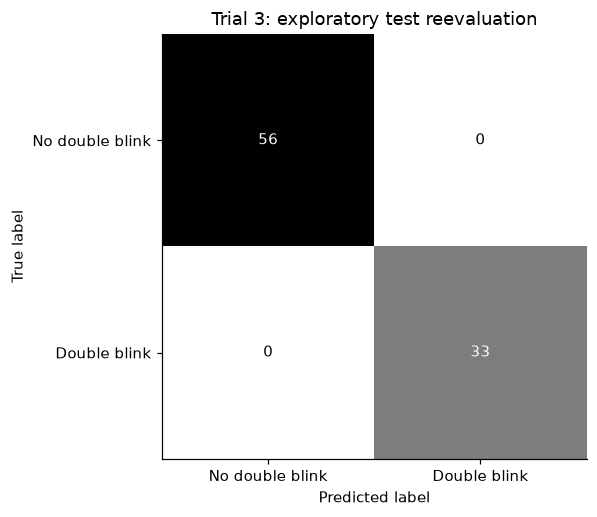

In [12]:
final_model = clone(fitted[best_name]).fit(np.vstack([X_train, X_valid]), np.concatenate([y_train, y_valid]))
test_predictions = final_model.predict(X_test)
test_scores = prediction_scores(final_model, X_test)
test_metrics = evaluate(y_test, test_predictions, test_scores)
baseline_metrics = evaluate(y_test, np.zeros_like(y_test), np.zeros_like(y_test, dtype=float))
display(pd.DataFrame({"Selected model": test_metrics, "Always no double blink": baseline_metrics}).style.format("{:.3f}"))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=[0, 1],
    display_labels=["No double blink", "Double blink"], cmap="Greys", colorbar=False)
plt.title("Trial 3: exploratory test reevaluation")
plt.tight_layout()
plt.show()

In [13]:
prediction_table = manifest.loc[test_mask].reset_index(drop=True).copy()
prediction_table["predicted"], prediction_table["score"] = test_predictions, test_scores
negative = prediction_table.loc[prediction_table["label"].eq(0)]
false_positives = negative.groupby("stimulus_type")["predicted"].agg(epochs="size", false_positives="sum")
false_positives["false_positive_rate"] = false_positives["false_positives"] / false_positives["epochs"]
display(false_positives.style.format({"false_positive_rate": "{:.1%}"}))

,epochs,false_positives,false_positive_rate
stimulus_type,,,
blank,45,0,0.0%
na,11,0,0.0%


## 9. Save

In [14]:
preprocessing = {
    "clock_offset_s": CLOCK_OFFSET_S, "clock_alignment": "approximate visual alignment on Trials 1–2",
    "dropped_channels": DROP_CHANNELS, "bandpass_hz": BANDPASS, "filter_method": "iir",
    "filter_type": "butterworth", "filter_order": FILTER_ORDER, "filter_phase": "zero",
    "sample_rate_hz": SAMPLE_RATE, "reference": "original", "ica": False,
    "interpolate_bads": False, "epoch_seconds": EPOCH_SECONDS,
    "baseline_seconds": [-BASELINE_SECONDS, 0], "baseline_endpoint": "excludes onset",
    "epoch_policy": "one full post-onset epoch per event; ceil to next sample",
}
report = {
    "experiment": 3, "train_trials": [TRAIN_TRIAL], "validation_trial": VALID_TRIAL,
    "test_trial": TEST_TRIAL, "refit_trials": [TRAIN_TRIAL, VALID_TRIAL],
    "test_status": "Exploratory reevaluation of a previously inspected test recording",
    "selected_model": best_name, "selected_pipeline": str(final_model),
    "validation_balanced_accuracy": float(validation_results.iloc[0]["Balanced accuracy"]),
    "train_epochs": len(y_train), "validation_epochs": len(y_valid), "test_epochs": len(y_test),
    "channels": MODEL_CHANNELS, "display_channels": display_channels,
    "input_shape": list(X.shape[1:]), "input_units": "microvolts", "time_bin_seconds": BIN_SECONDS,
    "preprocessing": preprocessing, "sources": sources, "test_metrics": test_metrics,
    "always_negative": baseline_metrics, "confusion_matrix": confusion_matrix(y_test, test_predictions).tolist(),
    "false_positives": false_positives.reset_index().to_dict(orient="records"),
    "notes": ["Cue labels describe instructed actions, not independently measured blink times.",
              "Trial 3 did not determine clock correction or model settings.",
              "Analysis uses all 21 remaining channels; the demo retains its separate two-channel model."],
}

In [15]:
OUTPUT.mkdir(parents=True, exist_ok=True)
for trial in TRIALS:
    cleaned[trial].save(OUTPUT / f"trial_{trial}_preprocessed_raw.fif", overwrite=True, verbose="error")
    epochs[trial].save(OUTPUT / f"trial_{trial}-epo.fif", overwrite=True, verbose="error")
manifest.to_csv(OUTPUT / "epoch_split.csv", index=False)
prediction_table.to_csv(OUTPUT / "test_predictions.csv", index=False)
validation_results.to_csv(OUTPUT / "validation_results.csv")
pd.DataFrame(sources).to_csv(OUTPUT / "alignment.csv", index=False)
np.savez_compressed(OUTPUT / "epochs.npz", X=X, y=y, trial=manifest["trial"].to_numpy(),
                    split=manifest["split"].to_numpy(dtype=str), channels=np.array(MODEL_CHANNELS), sfreq=SAMPLE_RATE)
(OUTPUT / "metrics.json").write_text(json.dumps(report, indent=2) + "\n")
artifact = {"pipeline": final_model, "channels": MODEL_CHANNELS, "display_channels": display_channels,
            "input_shape": list(X.shape[1:]), "input_units": "microvolts", "preprocessing": preprocessing,
            "time_bin_seconds": BIN_SECONDS, "labels": {0: "no double blink", 1: "double blink"}}
with (OUTPUT / "blink_classifier.pkl").open("wb") as file:
    cloudpickle.dump(artifact, file)
with (OUTPUT / "blink_classifier.pkl").open("rb") as file:
    reloaded = cloudpickle.load(file)["pipeline"]
np.testing.assert_array_equal(reloaded.predict(X_test), test_predictions)
np.testing.assert_allclose(prediction_scores(reloaded, X_test), test_scores)
print(f"Saved to {OUTPUT}; reloaded predictions verified.")

Saved to /Users/ajayvikram/Desktop/ML/neurotech/results/blink_pipeline_all_channels; reloaded predictions verified.
